Preamble

Run the setup cell below once from the repository folder to install the SIC dependencies into this notebook's Python environment. Restart the kernel after installation, then continue with the imports.

In [ ]:
%pip install -e ".[sic]"

In [1]:
%reload_ext autoreload
%autoreload 2

import importlib
import mplc.data as mplc_data

# Refresh dataset classes when rerunning after a source-code change.
importlib.reload(mplc_data)

from mplc import MPLC
from mplc.data import SICFieldDataset, get_basis_fields, get_basis_fields_pos, RandomFieldDataset
import mplc.functional as mplcF
import torch

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

Define MPLC specs

In [2]:
max_size = 5e-3 # width of the phase masks ; m
beam_waist = 0.8e-3 # beam waist of the laser ; m
wavelength = 810e-9 # wavelength of laser ; m
spacing = 5e-6 #  size of the pixels used in the simulation ; m

shape = round(max_size / spacing) # avoid floating-point floor division dropping a pixel
print('Initializing', shape, 'pixels.')

mask_spacing = 15e-6 # size of the phase mask pixels (greater or equal to the size of the simulation pixels) ; m
num_masks = 8 # number of masks
propagation_distance = 0.1 # distance between each mask ; m


# Use CUDA when available; otherwise use the CPU.
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")
dtype = torch.complex64 # match the SIC kets and basis fields returned by mplc.data

Initializing 1000 pixels.
Using cuda device


Define the target gate, and create an associated dataset.

In [5]:
def xgate(D,m):
    
    # D = torch.tensor(D)
    # m = torch.tensor(m)
    x_matrix = torch.eye(D, dtype=dtype, device=device)
    x_matrix = torch.roll(x_matrix,m,0)
    return x_matrix


dimension = 4 # dimension of the target gate
# target = mplcF.hadamard(dimension) # target gate in matrix form
target = xgate(dimension,1)
separation = 1.2 # separation of the logical basis fields: |k_j> = |separation*j>
basis_fields = get_basis_fields(dimension, shape, spacing, beam_waist, device, separation) # list of fields specifying the logical basis. transverse k-modes in our implementation
# basis_fields = get_basis_fields_pos(dimension, shape, spacing, beam_waist, device, separation = separation)

dataset = SICFieldDataset(target, basis_fields)  # the minimal, symmetric dataset which completely specifies the target gate
batch_size = 16 # since our dataset only has 16 elements in this example, we can use all the datapoints each epoch. For larger datasets, keep this smaller. 
dataloader = dataset.get_dataloader(batch_size) # this object passes the dataset to the model with the appropriate batching, shuffling, etc.

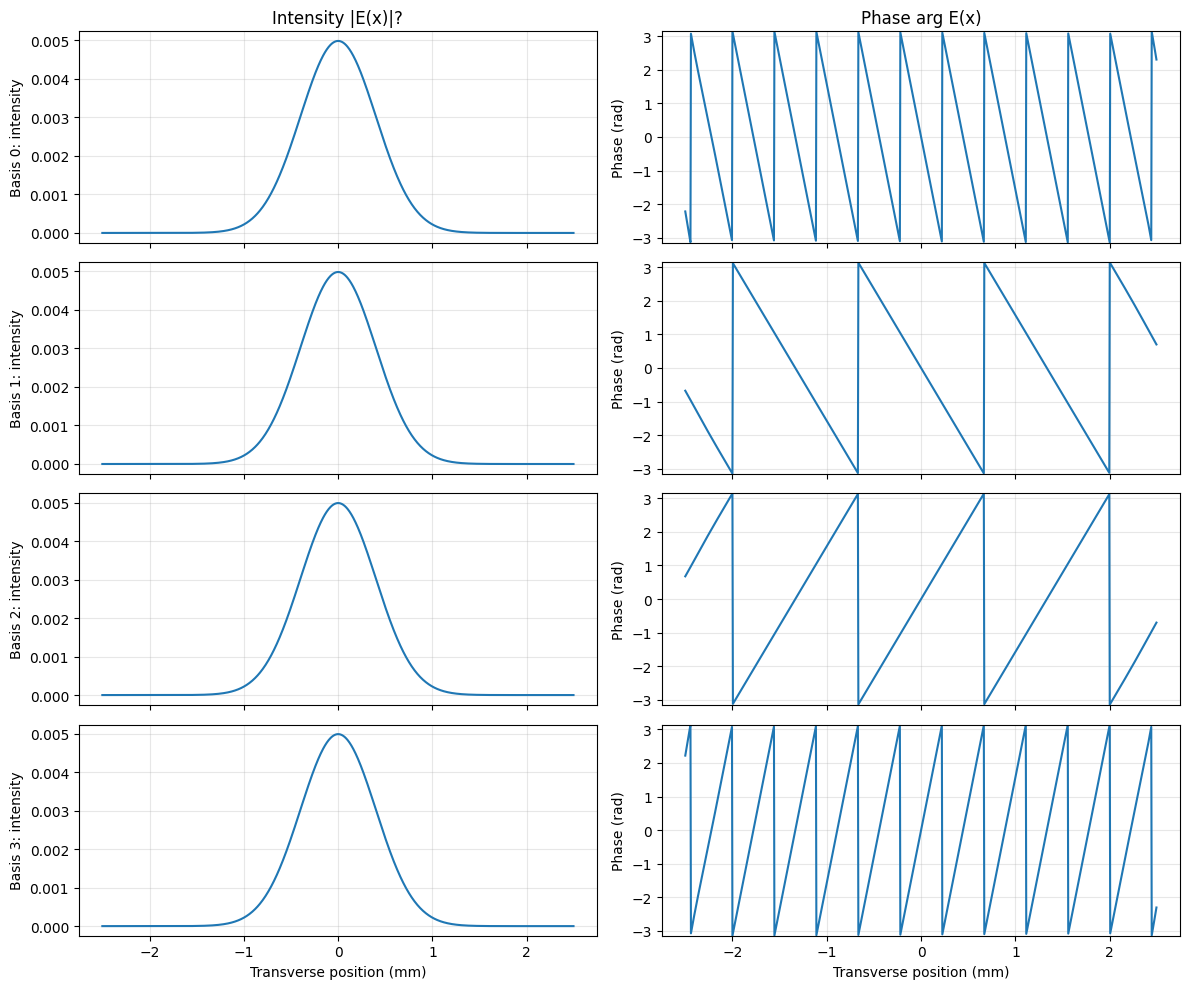

In [6]:
# Plot the intensity and phase of each logical basis field.
fields = basis_fields.detach().cpu().numpy()
num_fields, num_pixels = fields.shape
x_mm = (np.arange(num_pixels) - (num_pixels + 1) // 2) * spacing * 1e3

fig, axes = plt.subplots(
    num_fields, 2, figsize=(12, 2.5 * num_fields), sharex=True, squeeze=False
)
for j, field in enumerate(fields):
    axes[j, 0].plot(x_mm, np.abs(field) ** 2)
    axes[j, 0].set_ylabel(f"Basis {j}: intensity")
    axes[j, 1].plot(x_mm, np.angle(field))
    axes[j, 1].set_ylabel("Phase (rad)")
    axes[j, 1].set_ylim(-np.pi, np.pi)
    for ax in axes[j]:
        ax.grid(True, alpha=0.3)

axes[0, 0].set_title("Intensity |E(x)|?")
axes[0, 1].set_title("Phase arg E(x)")
for ax in axes[-1]:
    ax.set_xlabel("Transverse position (mm)")
fig.tight_layout()
plt.show()


Create a model with the specs

In [7]:
smooth_weight = 0.5 # how harshly should the training penalize a large second derivative
init_scale = 1e-1 # the magnitude scale of the initial phase mask parameters


torch.manual_seed(89) # some seeds are luckier than others, especially for a large init_scale. if you're having trouble with convergence, try a few different seeds
model = MPLC(shape, spacing, mask_spacing, num_masks, propagation_distance, beam_waist, wavelength, device, smooth_weight, init_scale)

params_list = [{'params': model.phase_masks.parameters(), 'lr': 0.17, 'weight_decay': 0.025}]
optimizer = torch.optim.AdamW(params_list)
loss_func = mplcF.field_overlap_loss # given by 1- avg(|< psi_target | psi_output >|)

In [8]:
num_epochs = 200
model.train_mplc(num_epochs, dataloader, optimizer, device, loss_func)

Epoch 200 | Loss: 0.144228


Plot the training curve and phase masks

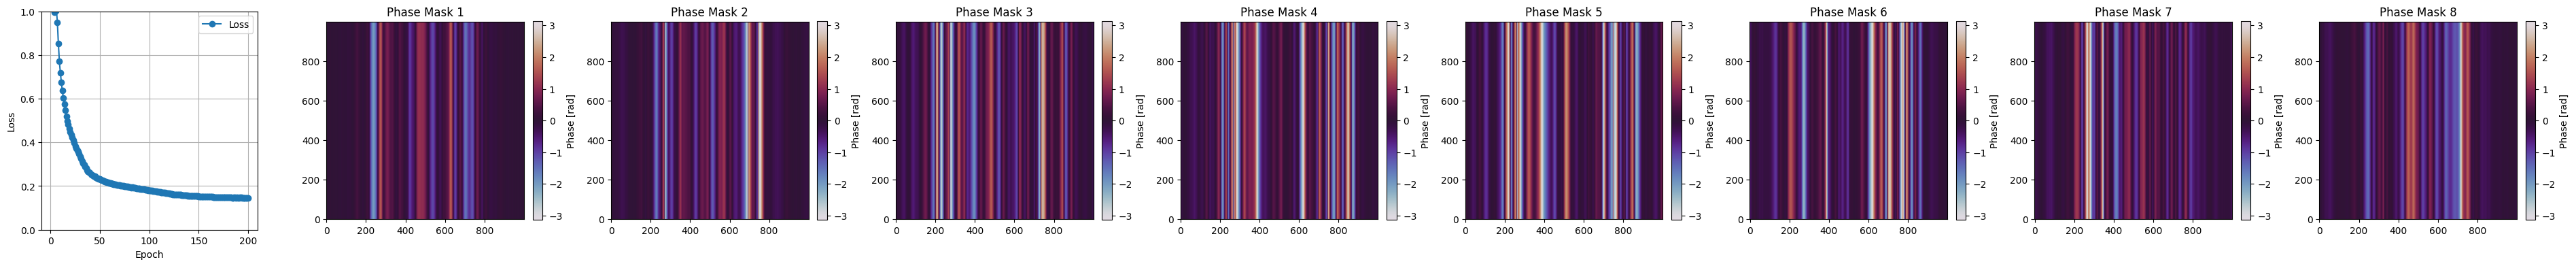

In [9]:
a = model.visualize_model(show = False)

Plot the propagation of each logical basis state through the MPLC, in either the near field or the far field.

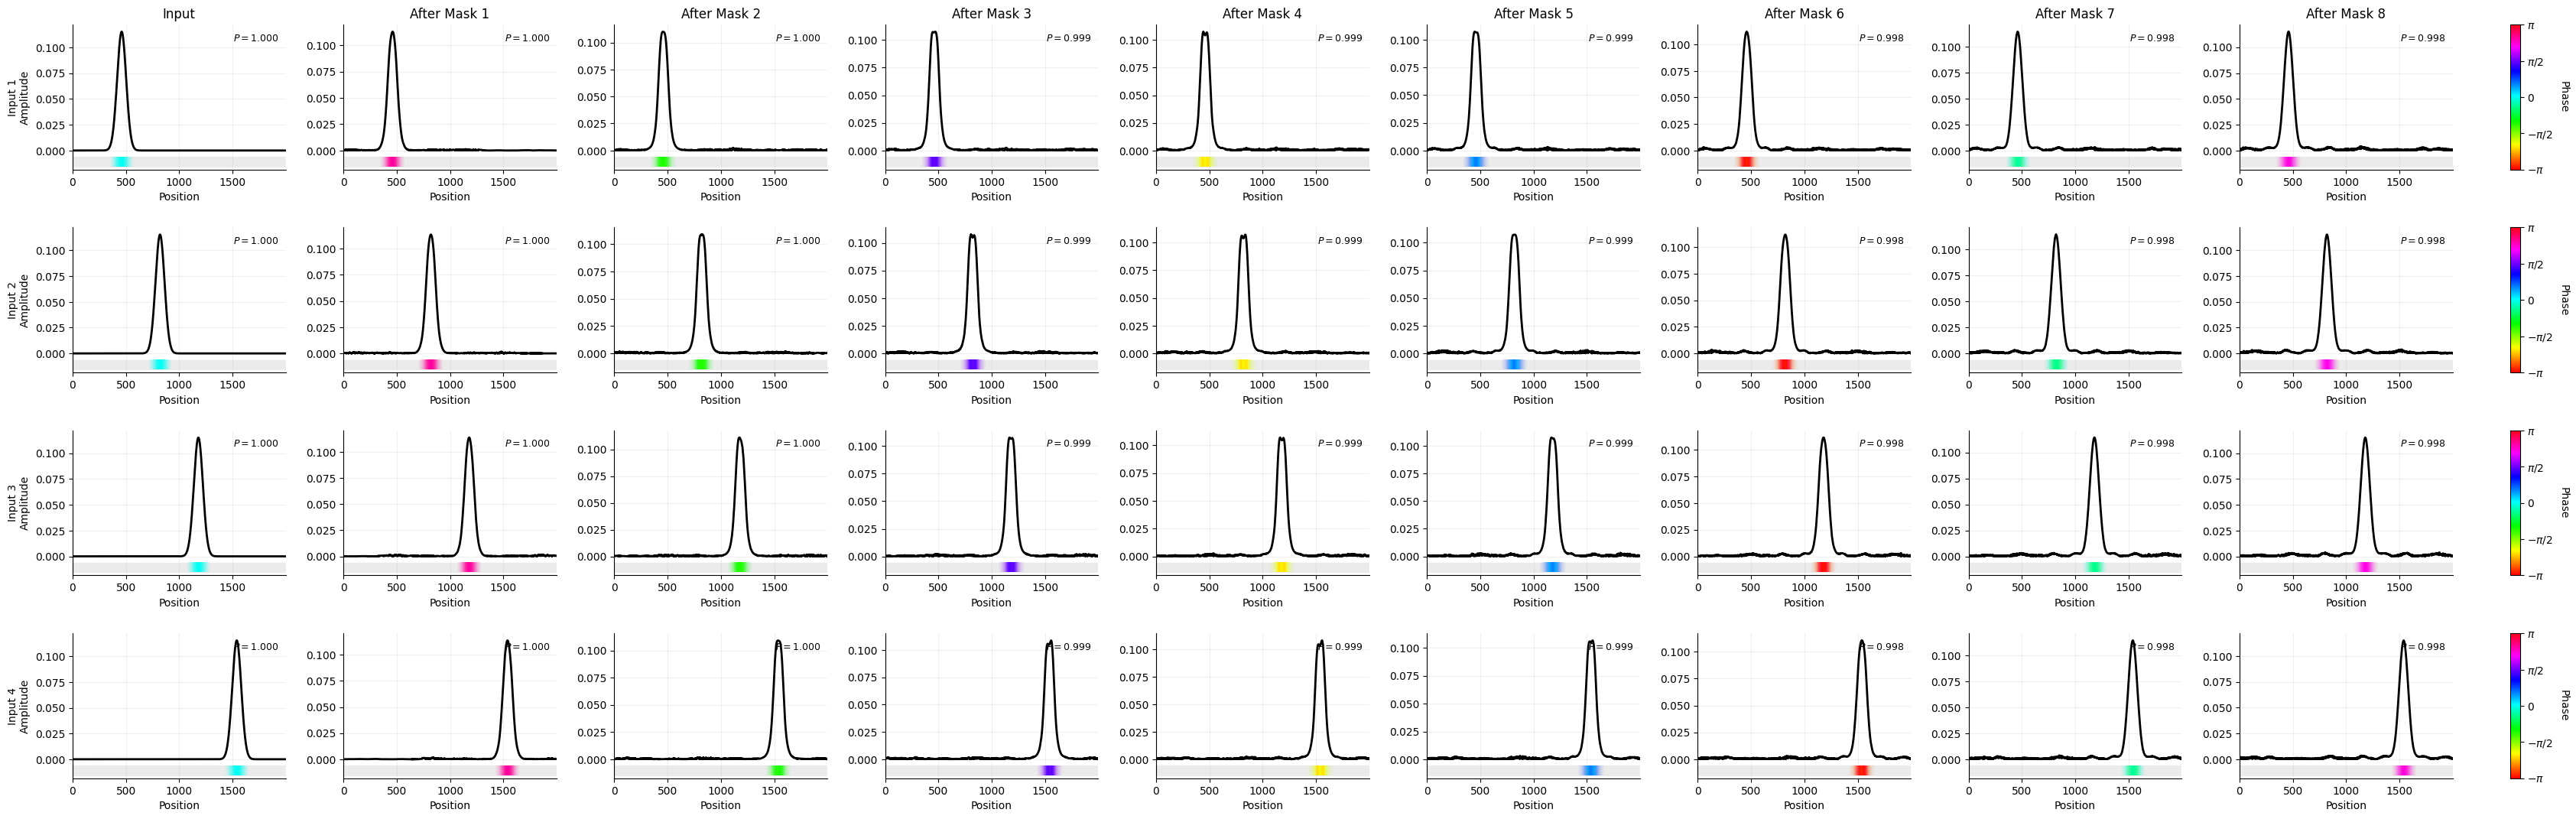

In [42]:
fig = model.visualize_field(basis_fields, far_field=False)

Plot the phase gradient across each mask, comparing it to the maximum of $\frac{\pi\;rad}{50\mu m}$.

TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.

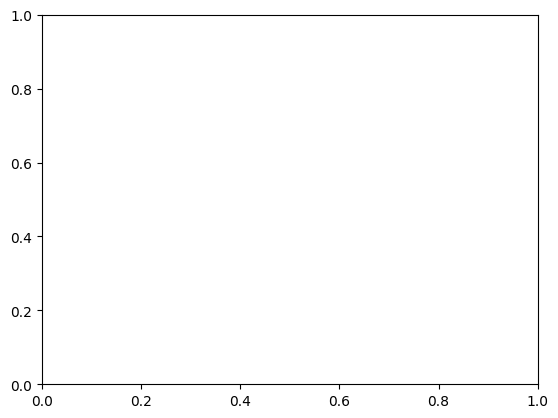

In [10]:
model.vizualize_phase_gradient()

The best figure of merit is the average performance across any states, not just SIC-POVM or logical states. 

In [ ]:
test_dataset = RandomFieldDataset(target, basis_fields, 1000) # 1000 states!
test_dataloader = test_dataset.get_dataloader(1) # don't use all the states at once, it will be very slow

test_loss = model.test(test_dataloader, loss_func)
print(1-test_loss)

Save your masks.

In [ ]:
model.export_masks("your/folder/name/here")